# Base model: which moments do people replay?

**Goal.** Learn, from YouTube "Most replayed" curves, which 15-second moments in a song people return to.
New users get these picks before the personal model knows their taste.

**How to read this notebook.** One section per research step. Each ends with a **Verdict** line.

| # | Step | Question | Status |
|---|---|---|---|
| 1 | Data | Is the data good enough? | ✅ done |
| 2 | Explore | Is there a pattern at all? | ✅ done |
| 3 | Baselines | How good are simple rules? | next |
| 4 | Train | Can the model learn? | |
| 5 | Evaluate | Does it beat the simple rules on unseen songs? | |
| 6 | Tune | Can better settings help? | |
| 7 | Understand | What did it learn? | |
| 8 | Decide | Keep it or drop it? | |

Research only: YouTube data is not cleared for a product model.

In [1]:
import json
from collections import Counter
import matplotlib.pyplot as plt
from musicdna.corpus.genre_mix import GenreMixManifest, GENRES, TIERS, OPENING_SEC

# Reference palette (dataviz skill): blue = has a replay curve, light grey = none.
HAS, NONE, INK, MUTED, GRID = '#2a78d6', '#d6d5d0', '#0b0b0b', '#52514e', '#e7e6e1'
plt.rcParams.update({'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'axes.edgecolor': GRID,
                     'axes.labelcolor': MUTED, 'xtick.color': MUTED, 'ytick.color': MUTED, 'text.color': INK,
                     'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10})

manifest = GenreMixManifest.load()
songs = manifest.entries
with_curve = [s for s in songs if s.replay_curve]
print(f'{len(songs)} songs, {len(with_curve)} with a replay curve, {sum(bool(s.audio_file) for s in songs)} downloaded')

120 songs, 92 with a replay curve, 120 downloaded


## Step 1 · Data

**Question:** does every genre have enough songs with a replay curve?

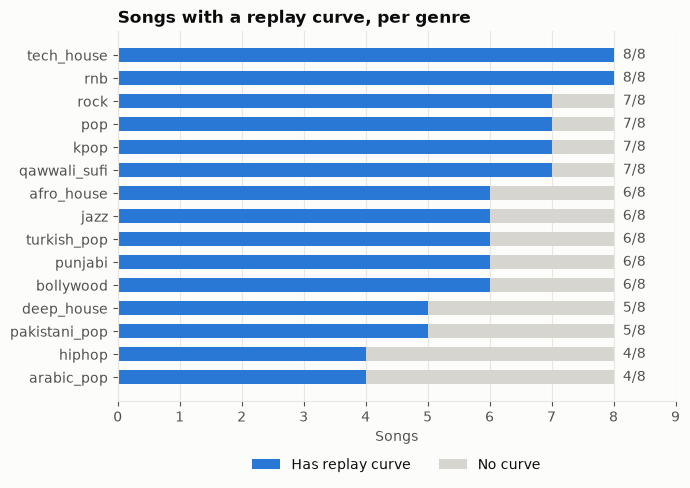

In [2]:
genres = sorted(GENRES, key=lambda g: sum(1 for s in with_curve if s.genre == g))
has = [sum(1 for s in with_curve if s.genre == g) for g in genres]
total = [sum(1 for s in songs if s.genre == g) for g in genres]

fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(genres, has, color=HAS, height=0.62, label='Has replay curve')
ax.barh(genres, [t - h for t, h in zip(total, has)], left=has, color=NONE, height=0.62, label='No curve')
for y, (h, t) in enumerate(zip(has, total)):
    ax.text(t + 0.15, y, f'{h}/{t}', va='center', color=MUTED)
ax.set_xlim(0, 9); ax.set_xlabel('Songs')
ax.set_title('Songs with a replay curve, per genre', loc='left', fontweight='bold')
ax.legend(frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=2); ax.grid(axis='x', color=GRID); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()

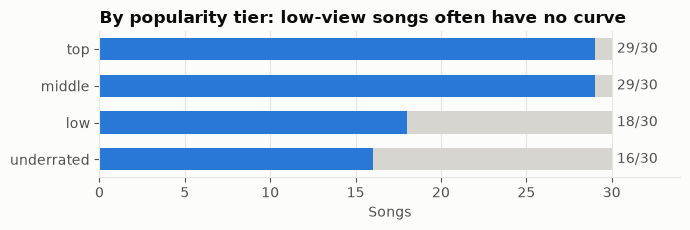

In [3]:
fig, ax = plt.subplots(figsize=(7, 2.4))
has_t = [sum(1 for s in with_curve if s.tier == t) for t in TIERS]
tot_t = [sum(1 for s in songs if s.tier == t) for t in TIERS]
ax.barh(TIERS[::-1], has_t[::-1], color=HAS, height=0.6)
ax.barh(TIERS[::-1], [t - h for t, h in zip(tot_t, has_t)][::-1], left=has_t[::-1], color=NONE, height=0.6)
for y, (h, t) in enumerate(zip(has_t[::-1], tot_t[::-1])):
    ax.text(t + 0.3, y, f'{h}/{t}', va='center', color=MUTED)
ax.set_xlim(0, 34); ax.set_xlabel('Songs')
ax.set_title('By popularity tier: low-view songs often have no curve', loc='left', fontweight='bold')
ax.grid(axis='x', color=GRID); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()

**What a replay curve looks like.** One song per region. The curve is 1.0 at the most replayed moment of that video.
The grey band is the opening, where every view starts, so it is high in every song and is ignored.

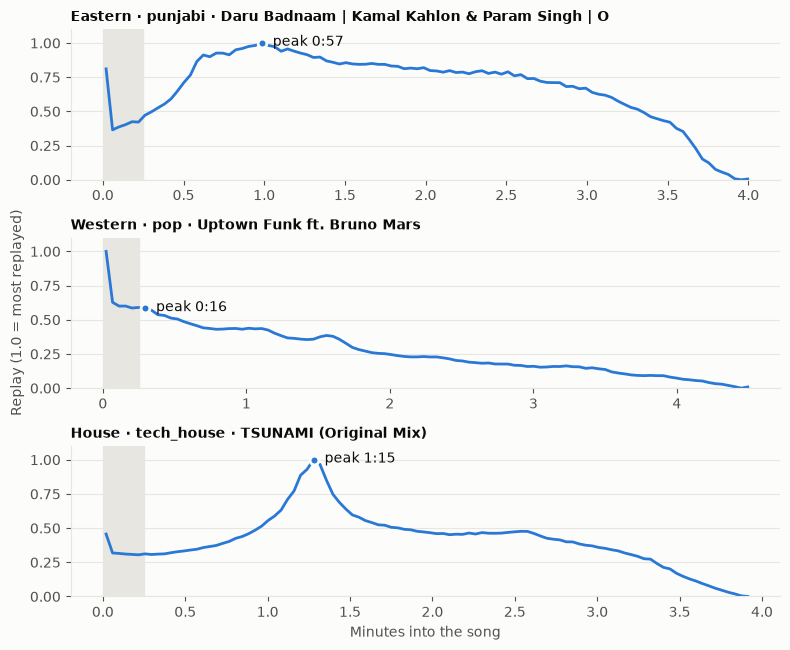

In [4]:
def example(region):
    pool = [s for s in with_curve if s.region == region and s.tier == 'top']
    return max(pool, key=lambda s: s.view_count)

fig, axes = plt.subplots(3, 1, figsize=(8, 6.6), sharey=True)
for ax, region in zip(axes, ['eastern', 'western', 'house']):
    s = example(region)
    x = [(a + b) / 2 / 60 for a, b, _ in s.replay_curve]
    y = [v for *_, v in s.replay_curve]
    after = [seg for seg in s.replay_curve if seg[0] >= OPENING_SEC]
    peak = max(after, key=lambda seg: seg[2])
    ax.axvspan(0, OPENING_SEC / 60, color=GRID)
    ax.plot(x, y, color=HAS, lw=2)
    ax.scatter([(peak[0] + peak[1]) / 2 / 60], [peak[2]], s=40, color=HAS, edgecolor='#fcfcfb', lw=2, zorder=3)
    m, sec = divmod(int(peak[0]), 60)
    ax.annotate(f'peak {m}:{sec:02d}', ((peak[0] + peak[1]) / 2 / 60, peak[2]), xytext=(8, -2),
                textcoords='offset points', color=INK)
    ax.set_title(f'{region.title()} · {s.genre} · {s.song[:45]}', loc='left', fontsize=10, fontweight='bold')
    ax.set_ylim(0, 1.1); ax.grid(axis='y', color=GRID); ax.set_axisbelow(True)
axes[-1].set_xlabel('Minutes into the song'); axes[1].set_ylabel('Replay (1.0 = most replayed)')
plt.tight_layout(); plt.show()

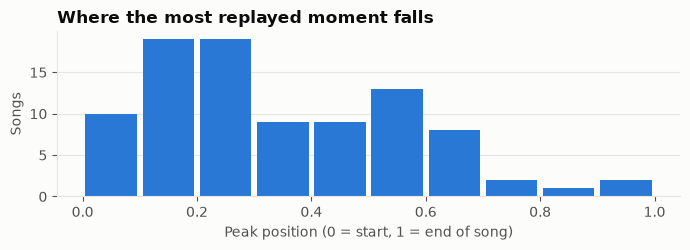

62% of peaks fall in the first 40% of the song


In [5]:
# Where do peaks fall? Position of each song's peak (after the opening), as a share of song length.
positions = []
for s in with_curve:
    after = [seg for seg in s.replay_curve if seg[0] >= OPENING_SEC]
    peak = max(after, key=lambda seg: seg[2])
    positions.append(peak[0] / s.replay_curve[-1][1])
fig, ax = plt.subplots(figsize=(7, 2.6))
ax.hist(positions, bins=10, range=(0, 1), color=HAS, rwidth=0.9)
ax.set_xlabel('Peak position (0 = start, 1 = end of song)'); ax.set_ylabel('Songs')
ax.set_title('Where the most replayed moment falls', loc='left', fontweight='bold')
ax.grid(axis='y', color=GRID); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()
early = sum(p < 0.4 for p in positions) / len(positions)
print(f'{early:.0%} of peaks fall in the first 40% of the song')

**Verdict (Step 1):** see the summary printed below. Every genre needs at least 4 songs with curves for a fair per-genre test.

In [6]:
per_genre = {g: sum(1 for s in with_curve if s.genre == g) for g in GENRES}
weakest = min(per_genre, key=per_genre.get)
ok = all(v >= 4 for v in per_genre.values())
print(f'{len(with_curve)}/{len(songs)} songs have curves. Weakest genre: {weakest} ({per_genre[weakest]}).')
print('PASS: every genre has at least 4 songs with curves.' if ok else 'FAIL: some genres have fewer than 4.')

92/120 songs have curves. Weakest genre: arabic_pop (4).
PASS: every genre has at least 4 songs with curves.


## Step 2 · Explore

**Question:** do replay peaks follow the *sound*, or only the *position* in the song?

Setup: features use 12-second windows with a 6-second hop. Each window gets the replay value of the curve under it.
Windows starting in the first 15 seconds are dropped.

In [7]:
import numpy as np
from scipy.stats import spearmanr
from musicdna.corpus.registry import get_corpus
from musicdna.experiments.replay_targets import PositionPrior, SongTargets

REGION_COLOR = {'eastern': '#2a78d6', 'western': '#eb6834', 'house': '#1baf7a'}  # palette slots 1-3
store = get_corpus('genre_mix').feature_store()
targets, feats = {}, {}
for s in with_curve:
    t = SongTargets.build(s.video_id, s.replay_curve, store.windows(s), store.duration(s))
    if len(t.index) < 8:
        continue
    targets[s.video_id] = t
    dsp = store.load(s.video_id, 'dsp')[t.index]
    feats[s.video_id] = {'loudness': store.load(s.video_id, 'loudness')[t.index, 0],
                         'brightness': dsp[:, 1], 'onset activity': dsp[:, 2]}
song_of = {s.video_id: s for s in with_curve}
print(f'{len(targets)} songs, {sum(len(t.index) for t in targets.values())} windows')

91 songs, 4166 windows


### 2a · How much of the curve is just position?

Average replay by position in the song (each song centred on its own mean). Drawn per region.

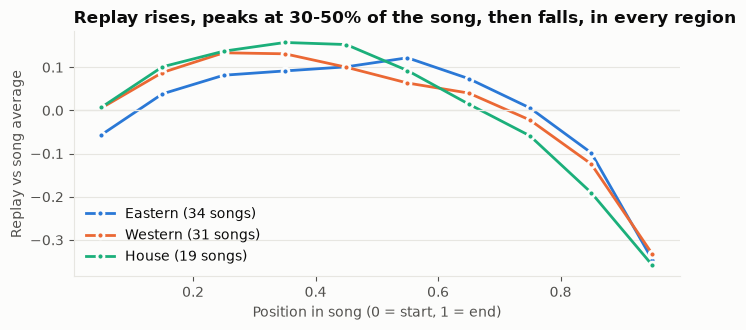

Position alone explains a median 70% of the within-song variation in replay.


In [8]:
fig, ax = plt.subplots(figsize=(7, 3.4))
centres = (np.arange(10) + 0.5) / 10
for region, color in REGION_COLOR.items():
    songs = [t for v, t in targets.items() if song_of[v].region == region]
    prior = PositionPrior().fit(songs)
    ax.plot(centres, prior.bin_means, color=color, lw=2, marker='o', ms=5, mec='#fcfcfb', mew=2,
            label=f'{region.title()} ({len(songs)} songs)')
ax.axhline(0, color=GRID, lw=1)
ax.set_xlabel('Position in song (0 = start, 1 = end)'); ax.set_ylabel('Replay vs song average')
ax.set_title('Replay rises, peaks at 30-50% of the song, then falls, in every region', loc='left', fontweight='bold')
ax.legend(frameon=False); ax.grid(axis='y', color=GRID); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()

prior_all = PositionPrior().fit(list(targets.values()))
explained = []
for t in targets.values():
    centred = t.replay - t.replay.mean()
    explained.append(1 - np.var(centred - prior_all.predict(t)) / np.var(centred) if np.var(centred) else 0)
print(f'Position alone explains a median {np.median(explained):.0%} of the within-song variation in replay.')

### 2b · One song: replay next to loudness

Top: replay. Bottom: loudness. Same time axis, two separate charts.

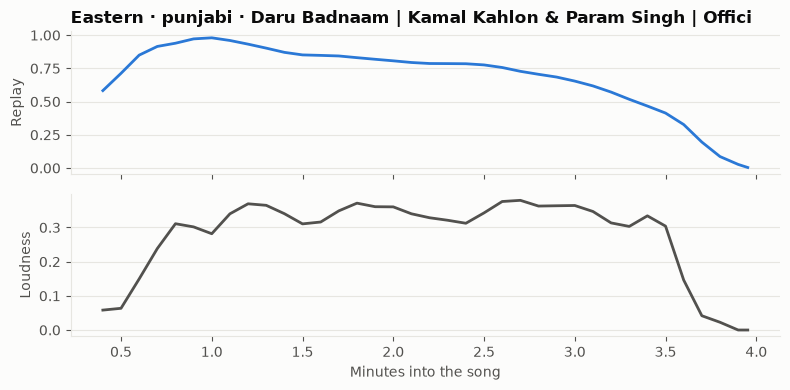

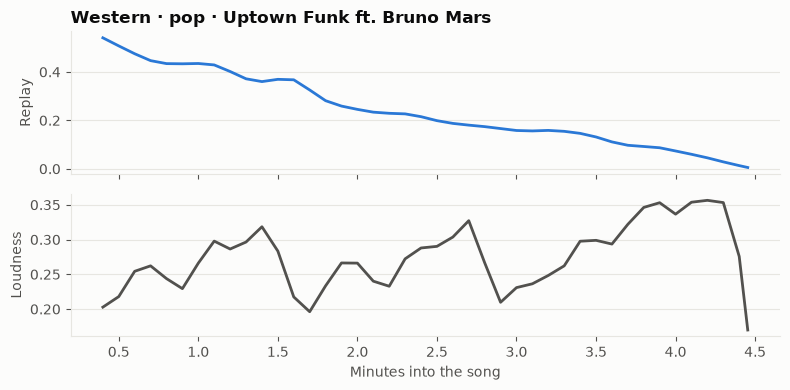

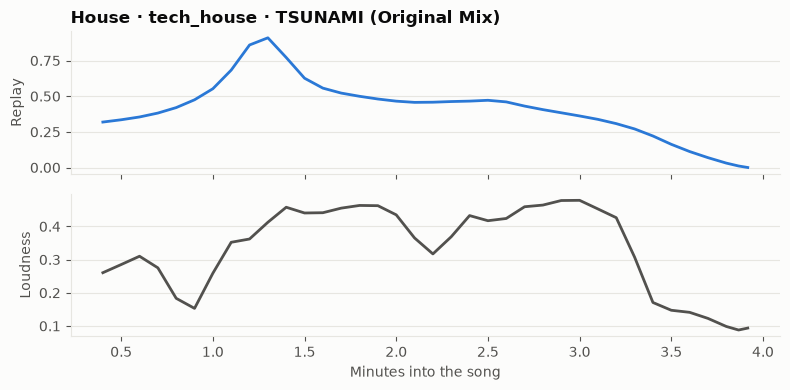

In [9]:
def show(video_id):
    s, t = song_of[video_id], targets[video_id]
    windows = store.windows(s)
    mins = np.array([(windows[i][0] + windows[i][1]) / 2 for i in t.index]) / 60
    fig, (a, b) = plt.subplots(2, 1, figsize=(8, 4), sharex=True)
    a.plot(mins, t.replay, color=HAS, lw=2); a.set_ylabel('Replay')
    a.set_title(f'{s.region.title()} · {s.genre} · {s.song[:50]}', loc='left', fontweight='bold')
    b.plot(mins, feats[video_id]['loudness'], color=MUTED, lw=2); b.set_ylabel('Loudness')
    b.set_xlabel('Minutes into the song')
    for ax in (a, b): ax.grid(axis='y', color=GRID); ax.set_axisbelow(True)
    plt.tight_layout(); plt.show()

for region in ['eastern', 'western', 'house']:
    pool = [v for v in targets if song_of[v].region == region and song_of[v].tier == 'top']
    show(max(pool, key=lambda v: song_of[v].view_count))

### 2c · Does the sound line up with replay once position is removed?

For each song: rank correlation (Spearman ρ) between a sound feature and *residual* replay (replay that position does not explain).
Dot = median over songs; bar = 95% bootstrap interval over songs. Right of zero = more replay where the feature is higher.

The position prior is fitted on all songs here. That is fine for exploring; Step 3 onward fits it on training songs only.

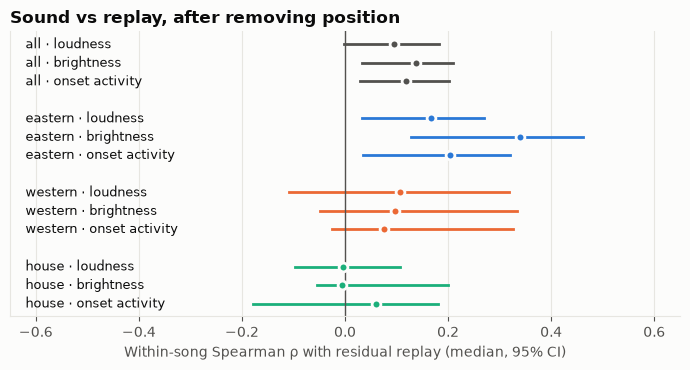

all      loudness        ρ = +0.09  [-0.00, +0.18]  (91 songs)
all      brightness      ρ = +0.14  [+0.03, +0.21]  (91 songs)
all      onset activity  ρ = +0.12  [+0.03, +0.20]  (91 songs)
eastern  loudness        ρ = +0.17  [+0.03, +0.27]  (34 songs)
eastern  brightness      ρ = +0.34  [+0.13, +0.46]  (34 songs)
eastern  onset activity  ρ = +0.20  [+0.03, +0.32]  (34 songs)
western  loudness        ρ = +0.11  [-0.11, +0.32]  (31 songs)
western  brightness      ρ = +0.10  [-0.05, +0.33]  (31 songs)
western  onset activity  ρ = +0.08  [-0.03, +0.33]  (31 songs)
house    loudness        ρ = -0.00  [-0.10, +0.11]  (19 songs)
house    brightness      ρ = -0.01  [-0.05, +0.20]  (19 songs)
house    onset activity  ρ = +0.06  [-0.18, +0.18]  (19 songs)


In [10]:
rng = np.random.default_rng(0)
FEATURES = ['loudness', 'brightness', 'onset activity']

def song_rhos(feature, region=None):
    out = []
    for v, t in targets.items():
        if region and song_of[v].region != region:
            continue
        r = spearmanr(feats[v][feature], prior_all.residual(t)).statistic
        if not np.isnan(r):
            out.append(r)
    return np.array(out)

def median_ci(values):
    boots = [np.median(rng.choice(values, len(values))) for _ in range(2000)]
    return np.median(values), *np.percentile(boots, [2.5, 97.5])

rows = []
fig, ax = plt.subplots(figsize=(7, 3.8))
groups = ['all', 'eastern', 'western', 'house']
for gi, group in enumerate(groups):
    for fi, feature in enumerate(FEATURES):
        rhos = song_rhos(feature, None if group == 'all' else group)
        m, lo, hi = median_ci(rhos)
        rows.append((group, feature, m, lo, hi, len(rhos)))
        y = gi * (len(FEATURES) + 1) + fi
        color = '#52514e' if group == 'all' else REGION_COLOR[group]
        ax.plot([lo, hi], [y, y], color=color, lw=2)
        ax.scatter([m], [y], color=color, s=40, edgecolor='#fcfcfb', lw=2, zorder=3)
        ax.text(-0.62, y, f'{group} · {feature}', va='center', ha='left', fontsize=9, color=INK)
ax.axvline(0, color=MUTED, lw=1)
ax.set_xlim(-0.65, 0.65); ax.set_yticks([]); ax.invert_yaxis()
ax.set_xlabel('Within-song Spearman ρ with residual replay (median, 95% CI)')
ax.set_title('Sound vs replay, after removing position', loc='left', fontweight='bold')
ax.grid(axis='x', color=GRID); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()
for g, f, m, lo, hi, n in rows:
    print(f'{g:<8} {f:<15} ρ = {m:+.2f}  [{lo:+.2f}, {hi:+.2f}]  ({n} songs)')

### 2d · Hard cases for later

Pairs of windows in the same song where one is clearly more replayed (residual gap > 0.1).
How often is the more replayed window the **quieter** one? These pairs cannot be won by loudness, so Step 5 reports them separately.

In [11]:
quieter = total = 0
for v, t in targets.items():
    res, loud = prior_all.residual(t), feats[v]['loudness']
    i, j = np.triu_indices(len(res), 1)
    gap = res[i] - res[j]
    keep = np.abs(gap) > 0.1
    more, less = np.where(gap[keep] > 0, i[keep], j[keep]), np.where(gap[keep] > 0, j[keep], i[keep])
    quieter += int(np.sum(loud[more] < loud[less])); total += int(keep.sum())
print(f'{total} clear pairs; the more replayed window is quieter in {quieter / total:.0%} of them.')

62154 clear pairs; the more replayed window is quieter in 47% of them.


**Verdict (Step 2):** printed below.

In [12]:
loud_all = next(r for r in rows if r[0] == 'all' and r[1] == 'loudness')
print(f'Position explains a median {np.median(explained):.0%} of within-song replay variation.')
print(f'After removing position, loudness vs replay: ρ = {loud_all[2]:+.2f} [{loud_all[3]:+.2f}, {loud_all[4]:+.2f}].')
signal = any(r[3] > 0 or r[4] < 0 for r in rows if r[0] == 'all')
print('PASS: at least one sound feature lines up with replay beyond position.' if signal
      else 'NO CLEAR SIGNAL from these simple features; the model will have to find it in CLAP and richer features.')

Position explains a median 70% of within-song replay variation.
After removing position, loudness vs replay: ρ = +0.09 [-0.00, +0.18].
PASS: at least one sound feature lines up with replay beyond position.


## Step 3 · Baselines *(next)*

Score simple rules on held-out songs: random, loudest, early, later, position prior, chorus/repetition.

## Decide · Confirmation test (H1, H2)

**Question:** on fresh songs, does `full` (fine-pitch, Sa-aligned features) beat `western`?

Trained on all 92 main-set songs, scored once on 85 confirmation songs, 5 seeds. Each bar is the paired difference `full` − `western` in pairwise accuracy, with a 95% bootstrap interval over songs. H1 needs the Eastern bar's interval above 0. H2 needs the asymmetry bar's interval above 0.

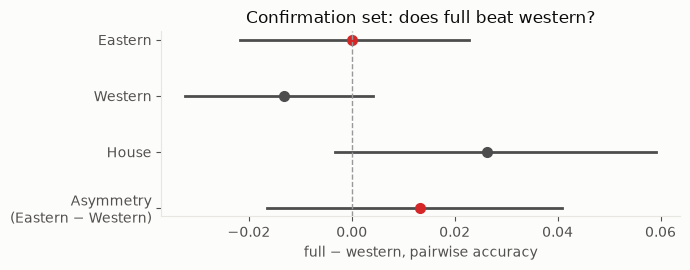

In [13]:
from pathlib import Path
run = json.loads(sorted(Path('../research-output/runs').glob('*_genre_mix_on_genre_mix_confirm_full+western.json'))[-1].read_text())
cmp = run['comparisons']['full - western']
rows = ['eastern', 'western', 'house', 'asymmetry']
labels = ['Eastern', 'Western', 'House', 'Asymmetry\n(Eastern − Western)']
fig, ax = plt.subplots(figsize=(7, 2.8))
for y, r in enumerate(rows):
    d, (lo, hi) = cmp[r]['diff'], cmp[r]['ci95']
    ax.plot([lo, hi], [y, y], color='0.3', lw=2)
    ax.plot(d, y, 'o', color='C3' if r in ('eastern', 'asymmetry') else '0.3', ms=7)
ax.axvline(0, color='0.6', ls='--', lw=1)
ax.set_yticks(range(len(rows)), labels); ax.invert_yaxis()
ax.set_xlabel('full − western, pairwise accuracy')
ax.set_title('Confirmation set: does full beat western?')
plt.tight_layout(); plt.show()

**Verdict (Decide):** printed below.

In [14]:
above = lambda r: cmp[r]['ci95'][0] > 0
fmt = lambda r: f"{cmp[r]['diff']:+.3f} [{cmp[r]['ci95'][0]:+.3f}, {cmp[r]['ci95'][1]:+.3f}]"
print(f"H1 (Eastern gain): {fmt('eastern')} -> {'SUPPORTED' if above('eastern') else 'NOT SUPPORTED'}")
print(f"H2 (asymmetry):    {fmt('asymmetry')} -> {'SUPPORTED' if above('asymmetry') else 'NOT SUPPORTED'}")

H1 (Eastern gain): +0.000 [-0.022, +0.023] -> NOT SUPPORTED
H2 (asymmetry):    +0.013 [-0.017, +0.041] -> NOT SUPPORTED
